In [1]:
!pip install rdkit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 52.9 MB/s  0:00:00


In [2]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors
from rdkit.Chem import Crippen
import pandas as pd


def calculate_parameters(smiles_list):
    results = []

    for i, smiles in enumerate(smiles_list, start=1):
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            print(f"Invalid SMILES skipped: {smiles}")
            continue

        # Calculate molecular descriptors
        parameters = {
            "Compound": f"Compound {i}",
            "SMILES": smiles,
            "Molecular Weight (g/mol)": round(
                Descriptors.MolWt(mol), 2
            ),
            "LogP": round(
                Crippen.MolLogP(mol), 2
            ),
            "TPSA (Å²)": round(
                rdMolDescriptors.CalcTPSA(mol), 2
            ),
            "H-Bond Donors": Lipinski.NumHDonors(mol),
            "H-Bond Acceptors": Lipinski.NumHAcceptors(mol),
            "Rotatable Bonds": Lipinski.NumRotatableBonds(mol),
            "Heavy Atoms": Lipinski.HeavyAtomCount(mol),
            "Aromatic Rings": Lipinski.NumAromaticRings(mol),
            "Total Rings": Lipinski.RingCount(mol),
            "Fraction Csp3": round(
                rdMolDescriptors.CalcFractionCSP3(mol), 3
            ),
            "Molar Refractivity": round(
                Crippen.MolMR(mol), 2
            )
        }

        results.append(parameters)

    if not results:
        print("No valid molecules were entered.")
        return

    # Display results as a table
    df = pd.DataFrame(results)

    print("\n========== MOLECULAR DESCRIPTORS ==========\n")
    print(df.to_string(index=False))

    # Save results to CSV for QSAR analysis
    df.to_csv("molecular_descriptors.csv", index=False)
    print("\nResults saved to molecular_descriptors.csv")

    return df


# Interactive SMILES input
smiles_input = []

print("=== Molecular Parameter Calculator ===")
print("Enter one SMILES string per line.")
print("Type 'done' when finished.\n")

while True:
    smiles = input("Enter SMILES: ").strip()

    if smiles.lower() == "done":
        break

    if smiles:
        smiles_input.append(smiles)

# Calculate parameters
if smiles_input:
    descriptor_table = calculate_parameters(smiles_input)
else:
    print("No SMILES strings entered.")

=== Molecular Parameter Calculator ===
Enter one SMILES string per line.
Type 'done' when finished.

Enter SMILES: CC(=O)OC1=CC=CC=C1C(=O)O
Enter SMILES: done

========== MOLECULAR DESCRIPTORS ==========

  Compound                   SMILES  Molecular Weight (g/mol)  LogP  TPSA (Å²)  H-Bond Donors  H-Bond Acceptors  Rotatable Bonds  Heavy Atoms  Aromatic Rings  Total Rings  Fraction Csp3  Molar Refractivity
Compound 1 CC(=O)OC1=CC=CC=C1C(=O)O                    180.16  1.31       63.6              1                 3                2           13               1            1          0.111               44.71

Results saved to molecular_descriptors.csv


Common Molecular Nucleus Detector
Enter one SMILES string per line.
Type 'done' when you have entered all molecules.

Enter SMILES: C1CC1N2C=C(C(=O)C3=CC(=C(C=C32)N4CCNCC4)F)C(=O)O
Enter SMILES: CCN1C=C(C(=O)C2=CC(=C(C=C21)N3CCNCC3)F)C(=O)O
Enter SMILES: done

========== RESULTS ==========
Common nucleus (SMARTS):
[#7]1:&@[#6]:&@[#6]:&@[#6](:&@[#6]2:&@[#6]:&@1:&@[#6]:&@[#6](:&@[#6]:&@[#6]:&@2)-&!@[#7]1-&@[#6]-&@[#6]-&@[#7]-&@[#6]-&@[#6]-&@1)=&!@[#8&!R]

Number of atoms: 17
Number of bonds: 19


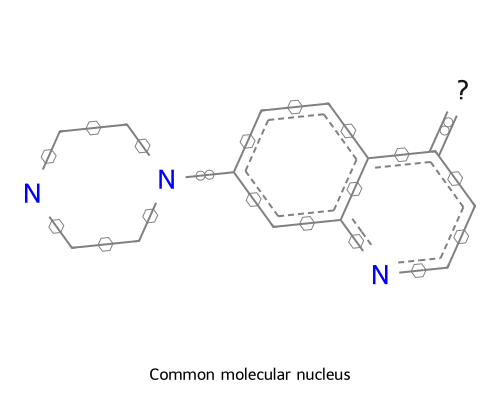

In [3]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import rdFMCS
from IPython.display import display


def identify_common_nucleus(smiles_list):
    molecules = []

    # Validate the SMILES inputs
    for i, smiles in enumerate(smiles_list, start=1):
        mol = Chem.MolFromSmiles(smiles)

        if mol is not None:
            molecules.append(mol)
        else:
            print(f"Invalid SMILES skipped: {smiles}")

    if len(molecules) < 2:
        print("Please provide at least two valid SMILES.")
        return

    # Extract Bemis-Murcko scaffolds
    scaffolds = [
        MurckoScaffold.GetScaffoldForMol(mol)
        for mol in molecules
    ]

    # Find the maximum common substructure
    result = rdFMCS.FindMCS(
        scaffolds,
        ringMatchesRingOnly=True,
        completeRingsOnly=True,
        matchValences=True,
        timeout=30
    )

    if result.canceled:
        print("The result may be incomplete.")

    if result.numAtoms == 0:
        print("No common scaffold found.")
        return

    # Generate and display the common structure
    common_mol = Chem.MolFromSmarts(result.smartsString)

    if common_mol is None:
        print("Could not generate the common structure.")
        return

    print("\n========== RESULTS ==========")
    print("Common nucleus (SMARTS):")
    print(result.smartsString)

    print("\nNumber of atoms:", result.numAtoms)
    print("Number of bonds:", result.numBonds)

    display(
        Draw.MolToImage(
            common_mol,
            size=(500, 400),
            legend="Common molecular nucleus"
        )
    )


# Interactive SMILES input system
smiles_input = []

print("Common Molecular Nucleus Detector")
print("Enter one SMILES string per line.")
print("Type 'done' when you have entered all molecules.\n")

while True:
    smiles = input("Enter SMILES: ").strip()

    if smiles.lower() == "done":
        break

    if smiles:
        smiles_input.append(smiles)

# Run the analysis
if len(smiles_input) >= 2:
    identify_common_nucleus(smiles_input)
else:
    print("Please enter at least two SMILES strings.")

In [8]:
from google.colab import files
uploaded = files.upload()

#--------------------------------------
#this program trains the model, calculates the R2, and on the basis of a new input calculates it's pIC50
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

# Load dataset
df = pd.read_csv("compound_data.csv")

# Descriptors (independent variables found in your uploaded file)
X = df[["MW","LogP","TPSA","HBD","HBA"]]

# Add dummy target variable since pIC50 is missing from the uploaded CSV
if "pIC50" not in df.columns:
    print("Warning: 'pIC50' column not found in CSV. Using dummy target values for demonstration.")
    df["pIC50"] = [5.5, 6.2, 4.8] # Replace these with your actual experimental data!

y = df["pIC50"]

# Train QSAR model
model = LinearRegression()
model.fit(X,y)

# Print QSAR equation
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

# Model accuracy
print("R2 score:", model.score(X,y))

print("\n--- Predict IC50 for a new compound ---")

# User input descriptors
MW = float(input("Molecular Weight: "))
LogP = float(input("LogP: "))
TPSA = float(input("TPSA: "))
HBD = float(input("HBD: "))
HBA = float(input("HBA: "))

# Create dataframe for prediction
new_data = pd.DataFrame([[MW,LogP,TPSA,HBD,HBA]],
columns=["MW","LogP","TPSA","HBD","HBA"])

# Predict pIC50
predicted_pIC50 = model.predict(new_data)[0]

# Convert pIC50 → IC50
IC50 = 10**(-predicted_pIC50)

print("\nPredicted pIC50:", predicted_pIC50)
print("Predicted IC50 (M):", IC50)

Saving compound_data.csv to compound_data (2).csv
Intercept: 490.9103270618158
Coefficients: [-2.42252087 -0.95706606  1.90858679 -0.15140755 -0.15140755]
R2 score: 1.0

--- Predict IC50 for a new compound ---
Molecular Weight: 447.4
LogP: 1.6
TPSA: 133
HBD: 0
HBA: 10

Predicted pIC50: -342.12884679586693
Predicted IC50 (M): inf


/tmp/ipykernel_438/3826294876.py:51: RuntimeWarning: overflow encountered in scalar power
  IC50 = 10**(-predicted_pIC50)
